In [54]:
# ============================================================
# CELL 1 — PROJECT SETUP
# ============================================================

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import tensorflow as tf

from tqdm.auto import tqdm

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("============================================")
print("CLASSROOM NOISE DETECTION")
print("DEEP LEARNING PROJECT")
print("============================================")

print("\nTensorFlow version:", tf.__version__)

print(
    "GPU:",
    tf.config.list_physical_devices("GPU")
)

CLASSROOM NOISE DETECTION
DEEP LEARNING PROJECT

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [55]:
# ============================================================
# CELL 2 — DATASET PATHS
# ============================================================

ZIP_PATH = "/content/ESC-50.zip"

DATASET_PATH = "/content/ESC-50-master"

AUDIO_PATH = os.path.join(
    DATASET_PATH,
    "audio"
)

METADATA_PATH = os.path.join(
    DATASET_PATH,
    "meta",
    "esc50.csv"
)

print("ZIP path:")
print(ZIP_PATH)

print("\nDataset path:")
print(DATASET_PATH)

print("\nAudio path:")
print(AUDIO_PATH)

print("\nMetadata path:")
print(METADATA_PATH)

ZIP path:
/content/ESC-50.zip

Dataset path:
/content/ESC-50-master

Audio path:
/content/ESC-50-master/audio

Metadata path:
/content/ESC-50-master/meta/esc50.csv


In [56]:
import os
import urllib.request

ZIP_PATH = "/content/ESC-50.zip"
URL = "https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip"

print("Downloading ESC-50 dataset...")

urllib.request.urlretrieve(URL, ZIP_PATH)

print("Download completed!")
print("File size:", round(os.path.getsize(ZIP_PATH) / (1024**2), 2), "MB")

Download completed!
File size: 615.78 MB


In [57]:
# EXTRACT ESC-50 DATASET

import os
import zipfile

ZIP_PATH = "/content/ESC-50.zip"

print("Extracting dataset...")

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall("/content")

DATASET_PATH = "/content/ESC-50-master"
METADATA_PATH = os.path.join(
    DATASET_PATH, "meta", "esc50.csv"
)
AUDIO_PATH = os.path.join(
    DATASET_PATH, "audio"
)

print("\nExtraction completed!")
print("Dataset folder exists:", os.path.exists(DATASET_PATH))
print("Metadata exists:", os.path.exists(METADATA_PATH))
print("Audio folder exists:", os.path.exists(AUDIO_PATH))

Extracting dataset...

Extraction completed!
Dataset folder exists: True
Metadata exists: True
Audio folder exists: True


In [58]:
# ============================================================
# CELL 4 — LOAD ESC-50 METADATA
# ============================================================



import pandas as pd
from IPython.display import display

df = pd.read_csv(METADATA_PATH)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (2000, 7)
Columns: ['filename', 'fold', 'target', 'category', 'esc10', 'src_file', 'take']


,filename,fold,target,category,esc10,src_file,take
0,1-100032-A-0.wav,1,0,dog,True,100032,A
1,1-100038-A-14.wav,1,14,chirping_birds,False,100038,A
2,1-100210-A-36.wav,1,36,vacuum_cleaner,False,100210,A
3,1-100210-B-36.wav,1,36,vacuum_cleaner,False,100210,B
4,1-101296-A-19.wav,1,19,thunderstorm,False,101296,A


In [59]:
# ============================================================
# CELL 5 — SELECT CLASSROOM-RELEVANT CLASSES
# ============================================================

SELECTED_CLASSES = [
    "clapping",
    "coughing",
    "door_wood_knock",
    "footsteps",
    "keyboard_typing",
    "laughing",
    "mouse_click",
    "breathing"
]

class_df = df[
    df["category"].isin(SELECTED_CLASSES)
].copy()

class_df = class_df.reset_index(drop=True)

print("Selected classroom classes:")
print("--------------------------------")

for i, class_name in enumerate(
    SELECTED_CLASSES,
    start=1
):
    print(f"{i}. {class_name}")

print("\nTotal selected samples:")
print(len(class_df))

print("\nClass distribution:")
display(
    class_df["category"]
    .value_counts()
    .sort_index()
)

Selected classroom classes:
--------------------------------
1. clapping
2. coughing
3. door_wood_knock
4. footsteps
5. keyboard_typing
6. laughing
7. mouse_click
8. breathing

Total selected samples:
320

Class distribution:


,count
category,
breathing,40
clapping,40
coughing,40
door_wood_knock,40
footsteps,40
keyboard_typing,40
laughing,40
mouse_click,40


In [60]:
# ============================================================
# CELL 6 — TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# ESC-50 official folds:
# Training   = folds 1, 2, 3
# Validation = fold 4
# Testing    = fold 5

train_df = class_df[
    class_df["fold"].isin([1, 2, 3])
].copy()

val_df = class_df[
    class_df["fold"] == 4
].copy()

test_df = class_df[
    class_df["fold"] == 5
].copy()

print("============================================")
print("DATASET SPLIT")
print("============================================")

print("Training samples   :", len(train_df))
print("Validation samples :", len(val_df))
print("Testing samples    :", len(test_df))
print("Total              :", len(train_df) + len(val_df) + len(test_df))

print("\nTraining distribution:")
display(
    train_df["category"]
    .value_counts()
    .sort_index()
)

print("\nValidation distribution:")
display(
    val_df["category"]
    .value_counts()
    .sort_index()
)

print("\nTesting distribution:")
display(
    test_df["category"]
    .value_counts()
    .sort_index()
)

DATASET SPLIT
Training samples   : 192
Validation samples : 64
Testing samples    : 64
Total              : 320

Training distribution:


,count
category,
breathing,24
clapping,24
coughing,24
door_wood_knock,24
footsteps,24
keyboard_typing,24
laughing,24
mouse_click,24



Validation distribution:


,count
category,
breathing,8
clapping,8
coughing,8
door_wood_knock,8
footsteps,8
keyboard_typing,8
laughing,8
mouse_click,8



Testing distribution:


,count
category,
breathing,8
clapping,8
coughing,8
door_wood_knock,8
footsteps,8
keyboard_typing,8
laughing,8
mouse_click,8


In [61]:
# ============================================================
# CELL 7 — LABEL ENCODING
# ============================================================

label_encoder = LabelEncoder()

label_encoder.fit(SELECTED_CLASSES)

train_df["label"] = label_encoder.transform(
    train_df["category"]
)

val_df["label"] = label_encoder.transform(
    val_df["category"]
)

test_df["label"] = label_encoder.transform(
    test_df["category"]
)

print("Class labels:")
print("--------------------------------")

for i, class_name in enumerate(
    label_encoder.classes_
):
    print(f"{i} → {class_name}")

print("\nNumber of classes:")
print(len(label_encoder.classes_))

Class labels:
--------------------------------
0 → breathing
1 → clapping
2 → coughing
3 → door_wood_knock
4 → footsteps
5 → keyboard_typing
6 → laughing
7 → mouse_click

Number of classes:
8


In [62]:
# ============================================================
# CELL 8 — MEL SPECTROGRAM FEATURE EXTRACTION
# ============================================================

SAMPLE_RATE = 22050
DURATION = 5
N_MELS = 128
N_FFT = 2048
HOP_LENGTH = 512

TARGET_FRAMES = 216


def extract_mel_spectrogram(file_path):

    # Load audio
    audio, sr = librosa.load(
        file_path,
        sr=SAMPLE_RATE,
        duration=DURATION
    )

    # Create Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS
    )

    # Convert power to dB
    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # Make every sample the same size
    if mel_db.shape[1] < TARGET_FRAMES:

        mel_db = np.pad(
            mel_db,
            (
                (0, 0),
                (0, TARGET_FRAMES - mel_db.shape[1])
            ),
            mode="constant"
        )

    else:

        mel_db = mel_db[
            :, :TARGET_FRAMES
        ]

    return mel_db.astype(np.float32)


print("Mel spectrogram function created successfully!")
print("Expected feature shape:")
print((N_MELS, TARGET_FRAMES))

Mel spectrogram function created successfully!
Expected feature shape:
(128, 216)


Sample file:
1-101336-A-30.wav

Class:
door_wood_knock

Mel spectrogram shape:
(128, 216)


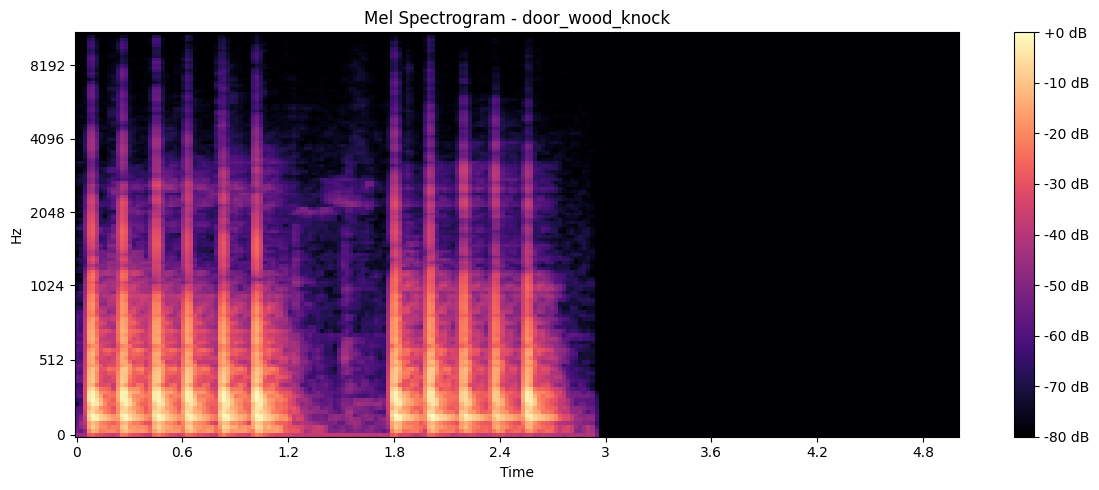

In [63]:
# ============================================================
# CELL 9 — TEST FEATURE EXTRACTION
# ============================================================

sample_row = train_df.iloc[0]

sample_file = os.path.join(
    AUDIO_PATH,
    sample_row["filename"]
)

sample_mel = extract_mel_spectrogram(
    sample_file
)

print("Sample file:")
print(sample_row["filename"])

print("\nClass:")
print(sample_row["category"])

print("\nMel spectrogram shape:")
print(sample_mel.shape)

plt.figure(figsize=(12, 5))

librosa.display.specshow(
    sample_mel,
    sr=SAMPLE_RATE,
    hop_length=HOP_LENGTH,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title(
    f"Mel Spectrogram - {sample_row['category']}"
)
plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# CELL 10 — EXTRACT FEATURES
# ============================================================

def build_feature_array(dataframe):

    features = []
    labels = []

    for _, row in tqdm(
        dataframe.iterrows(),
        total=len(dataframe)
    ):

        file_path = os.path.join(
            AUDIO_PATH,
            row["filename"]
        )

        mel = extract_mel_spectrogram(
            file_path
        )

        features.append(mel)
        labels.append(row["label"])

    return (
        np.array(features, dtype=np.float32),
        np.array(labels, dtype=np.int32)
    )


print("Extracting training features...")

X_train, y_train = build_feature_array(
    train_df
)

print("\nExtracting validation features...")

X_val, y_val = build_feature_array(
    val_df
)

print("\nExtracting testing features...")

X_test, y_test = build_feature_array(
    test_df
)

print("\n============================================")
print("FEATURE EXTRACTION COMPLETED")
print("============================================")

print("X_train:", X_train.shape)
print("X_val  :", X_val.shape)
print("X_test :", X_test.shape)

print("y_train:", y_train.shape)
print("y_val  :", y_val.shape)
print("y_test :", y_test.shape)

Extracting training features...


  0%|          | 0/192 [00:00<?, ?it/s]


Extracting validation features...


  0%|          | 0/64 [00:00<?, ?it/s]


Extracting testing features...


  0%|          | 0/64 [00:00<?, ?it/s]


FEATURE EXTRACTION COMPLETED
X_train: (192, 128, 216)
X_val  : (64, 128, 216)
X_test : (64, 128, 216)
y_train: (192,)
y_val  : (64,)
y_test : (64,)


In [65]:
# ============================================================
# CELL 11 — FEATURE NORMALIZATION
# ============================================================

# Calculate normalization parameters ONLY from training data

train_mean = X_train.mean()
train_std = X_train.std()

print("Training mean:", train_mean)
print("Training std :", train_std)

X_train = (
    X_train - train_mean
) / (train_std + 1e-8)

X_val = (
    X_val - train_mean
) / (train_std + 1e-8)

X_test = (
    X_test - train_mean
) / (train_std + 1e-8)

print("\nNormalization completed!")

print("Train mean after normalization:",
      X_train.mean())

print("Train std after normalization:",
      X_train.std())

Training mean: -53.448833
Training std : 21.537668

Normalization completed!
Train mean after normalization: -1.0345269e-06
Train std after normalization: 0.9999998


In [66]:
# ============================================================
# CELL 12 — PREPARE CNN INPUT
# ============================================================

X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("CNN input shapes")
print("--------------------------------")

print("X_train_cnn:", X_train_cnn.shape)
print("X_val_cnn  :", X_val_cnn.shape)
print("X_test_cnn :", X_test_cnn.shape)

CNN input shapes
--------------------------------
X_train_cnn: (192, 128, 216, 1)
X_val_cnn  : (64, 128, 216, 1)
X_test_cnn : (64, 128, 216, 1)


In [67]:
# ============================================================
# CELL 13 — SAVE PROCESSED FEATURES
# ============================================================

np.save(
    "/content/X_train.npy",
    X_train_cnn
)

np.save(
    "/content/X_val.npy",
    X_val_cnn
)

np.save(
    "/content/X_test.npy",
    X_test_cnn
)

np.save(
    "/content/y_train.npy",
    y_train
)

np.save(
    "/content/y_val.npy",
    y_val
)

np.save(
    "/content/y_test.npy",
    y_test
)

print("Processed datasets saved successfully!")

print("\nFiles created:")
print("X_train.npy")
print("X_val.npy")
print("X_test.npy")
print("y_train.npy")
print("y_val.npy")
print("y_test.npy")

Processed datasets saved successfully!

Files created:
X_train.npy
X_val.npy
X_test.npy
y_train.npy
y_val.npy
y_test.npy


In [68]:
# ============================================================
# CELL 14 — CNN MODEL
# ============================================================

from tensorflow.keras import layers, models

NUM_CLASSES = len(SELECTED_CLASSES)

cnn_model = models.Sequential([

    layers.Input(
        shape=(128, 216, 1)
    ),

    # Data augmentation
    layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),

    layers.RandomContrast(
        0.1
    ),

    # CNN Block 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Dropout(0.25),

    # CNN Block 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Dropout(0.30),

    # CNN Block 3
    layers.Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.BatchNormalization(),

    layers.MaxPooling2D(
        (2, 2)
    ),

    layers.Dropout(0.35),

    # Classification
    layers.GlobalAveragePooling2D(),

    layers.Dense(
        128,
        activation="relu"
    ),

    layers.Dropout(0.4),

    layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

cnn_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation_2            │ (None, 128, 216, 1)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_2               │ (None, 128, 216, 1)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 128, 216, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 128, 216, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 108, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 64, 108, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 32, 54, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32, 54, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 16, 27, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_15 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,112 (434.03 KB)

 Trainable params: 110,664 (432.28 KB)

 Non-trainable params: 448 (1.75 KB)

In [69]:
# CHECK CNN TRAINING VARIABLES

variables_to_check = [
    "cnn_model",
    "X_train_cnn",
    "X_val_cnn",
    "y_train",
    "y_val",
    "early_stopping",
    "reduce_lr",
    "checkpoint"
]

for name in variables_to_check:
    print(f"{name}: {'Available' if name in globals() else 'Missing'}")

cnn_model: Available
X_train_cnn: Available
X_val_cnn: Available
y_train: Available
y_val: Available
early_stopping: Available
reduce_lr: Available
checkpoint: Available


In [70]:
# RECREATE MISSING CNN TRAINING CALLBACKS

import tensorflow as tf

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-7,
    verbose=1
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath="/content/best_cnn_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

print("All three CNN callbacks recreated successfully!")

All three CNN callbacks recreated successfully!


In [71]:
# ============================================================
# CELL 16 — TRAIN CNN
# ============================================================

print("============================================")
print("STARTING CNN TRAINING")
print("============================================")

cnn_history = cnn_model.fit(

    X_train_cnn,
    y_train,

    validation_data=(
        X_val_cnn,
        y_val
    ),

    epochs=50,

    batch_size=16,

    callbacks=[
        early_stopping,
        reduce_lr,
        checkpoint
    ],

    verbose=1
)

print("\n============================================")
print("CNN TRAINING COMPLETED")
print("============================================")

STARTING CNN TRAINING
Epoch 1/50
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - accuracy: 0.2032 - loss: 2.1476
Epoch 1: val_loss improved from None to 1.99625, saving model to /content/best_cnn_model.keras

Epoch 1: finished saving model to /content/best_cnn_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 79ms/step - accuracy: 0.2552 - loss: 1.9637 - val_accuracy: 0.2500 - val_loss: 1.9963 - learning_rate: 0.0010
Epoch 2/50
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3200 - loss: 1.8314
Epoch 2: val_loss improved from 1.99625 to 1.97268, saving model to /content/best_cnn_model.keras

Epoch 2: finished saving model to /content/best_cnn_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 55ms/step - accuracy: 0.3750 - loss: 1.6934 - val_accuracy: 0.2656 - val_loss: 1.9727 - learning_rate: 0.0010
Epoch 3/50
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3722 - loss: 1.4952
Epoch 3: val_loss did not improve from 1.97268
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.4115 - loss: 1.5329

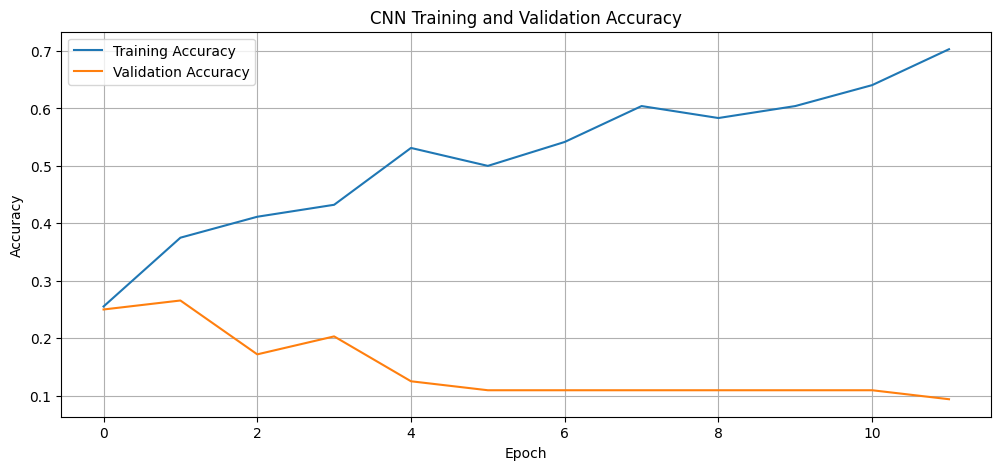

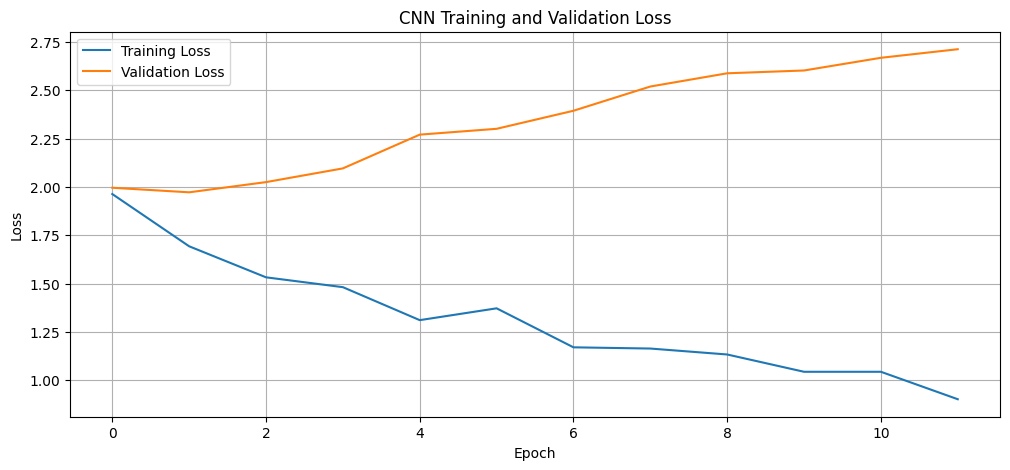

In [72]:
# ============================================================
# CELL 17 — CNN TRAINING GRAPHS
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(
    cnn_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    cnn_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(12, 5))

plt.plot(
    cnn_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    cnn_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()

In [73]:
# ============================================================
# CELL 18 — CNN TEST EVALUATION
# ============================================================

test_loss, test_accuracy = cnn_model.evaluate(
    X_test_cnn,
    y_test,
    verbose=1
)

print("\n============================================")
print("CNN TEST RESULT")
print("============================================")

print(
    f"Test Loss     : {test_loss:.4f}"
)

print(
    f"Test Accuracy : {test_accuracy * 100:.2f}%"
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1719 - loss: 2.0140 

CNN TEST RESULT
Test Loss     : 2.0140
Test Accuracy : 17.19%


In [74]:
# ============================================================
# CELL 19 — CNN CLASSIFICATION REPORT
# ============================================================

cnn_probabilities = cnn_model.predict(
    X_test_cnn,
    verbose=0
)

cnn_predictions = np.argmax(
    cnn_probabilities,
    axis=1
)

print(
    classification_report(
        y_test,
        cnn_predictions,
        target_names=label_encoder.classes_,
        digits=4
    )
)

                 precision    recall  f1-score   support

      breathing     0.2500    0.7500    0.3750         8
       clapping     1.0000    0.3750    0.5455         8
       coughing     0.0000    0.0000    0.0000         8
door_wood_knock     0.0000    0.0000    0.0000         8
      footsteps     0.0541    0.2500    0.0889         8
keyboard_typing     0.0000    0.0000    0.0000         8
       laughing     0.0000    0.0000    0.0000         8
    mouse_click     0.0000    0.0000    0.0000         8

       accuracy                         0.1719        64
      macro avg     0.1630    0.1719    0.1262        64
   weighted avg     0.1630    0.1719    0.1262        64



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


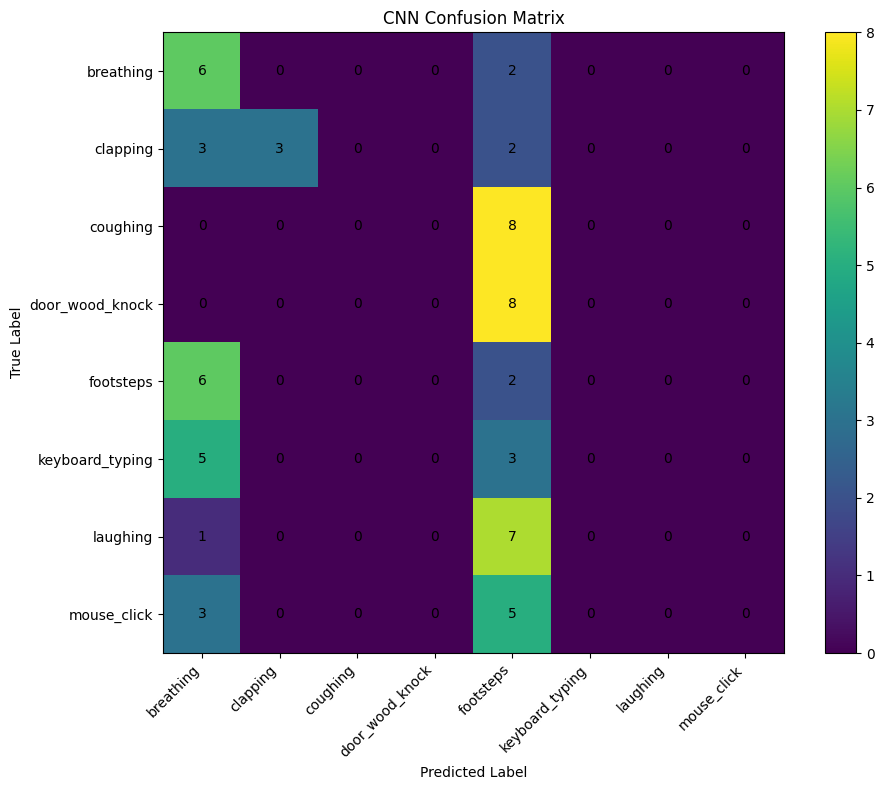

In [75]:
# ============================================================
# CELL 20 — CNN CONFUSION MATRIX
# ============================================================

cm_cnn = confusion_matrix(
    y_test,
    cnn_predictions
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm_cnn,
    interpolation="nearest"
)

plt.title("CNN Confusion Matrix")

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    label_encoder.classes_,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_cnn[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [76]:
# ============================================================
# CELL 21 — CNN PERFORMANCE METRICS
# ============================================================

cnn_accuracy = accuracy_score(
    y_test,
    cnn_predictions
)

cnn_precision = precision_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

cnn_recall = recall_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

cnn_f1 = f1_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

print("============================================")
print("CNN PERFORMANCE")
print("============================================")

print(
    f"Accuracy  : {cnn_accuracy * 100:.2f}%"
)

print(
    f"Precision : {cnn_precision * 100:.2f}%"
)

print(
    f"Recall    : {cnn_recall * 100:.2f}%"
)

print(
    f"F1 Score  : {cnn_f1 * 100:.2f}%"
)

CNN PERFORMANCE
Accuracy  : 17.19%
Precision : 16.30%
Recall    : 17.19%
F1 Score  : 12.62%


In [77]:
# ============================================================
# CELL 22 — CNN-LSTM MODEL
# ============================================================

from tensorflow.keras import Model

inputs = layers.Input(
    shape=(128, 216, 1)
)

# CNN feature extraction

x = layers.Conv2D(
    32,
    (3, 3),
    padding="same",
    activation="relu"
)(inputs)

x = layers.BatchNormalization()(x)

x = layers.MaxPooling2D(
    (2, 2)
)(x)

x = layers.Dropout(0.25)(x)


x = layers.Conv2D(
    64,
    (3, 3),
    padding="same",
    activation="relu"
)(x)

x = layers.BatchNormalization()(x)

x = layers.MaxPooling2D(
    (2, 2)
)(x)

x = layers.Dropout(0.3)(x)


# Current shape:
# 32 × 54 × 64

# Convert spectrogram features into sequences

x = layers.Permute(
    (2, 1, 3)
)(x)

x = layers.Reshape(
    (54, 32 * 64)
)(x)


# LSTM

x = layers.LSTM(
    64,
    return_sequences=False
)(x)

x = layers.Dropout(
    0.4
)(x)

x = layers.Dense(
    64,
    activation="relu"
)(x)

x = layers.Dropout(
    0.3
)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

cnn_lstm_model = Model(
    inputs,
    outputs
)

cnn_lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

cnn_lstm_model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 216, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 128, 216, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 128, 216, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_16 (Dropout)            │ (None, 64, 108, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 64, 108, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 64, 108, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_17 (Dropout)            │ (None, 32, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ permute_1 (Permute)             │ (None, 54, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 54, 2048)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │       540,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_19 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 564,808 (2.15 MB)

 Trainable params: 564,616 (2.15 MB)

 Non-trainable params: 192 (768.00 B)

In [78]:
# ============================================================
# CELL 23 — CNN-LSTM CALLBACKS
# ============================================================

import tensorflow as tf

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

cnn_lstm_early = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True,
    verbose=1
)

cnn_lstm_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=1e-6,
    verbose=1
)

cnn_lstm_checkpoint = ModelCheckpoint(
    filepath="/content/best_cnn_lstm_model.keras",
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

print("CNN-LSTM callbacks ready!")

CNN-LSTM callbacks ready!


In [79]:
# ============================================================
# CELL 24 — TRAIN CNN-LSTM
# ============================================================

print("============================================")
print("STARTING CNN-LSTM TRAINING")
print("============================================")

cnn_lstm_history = cnn_lstm_model.fit(

    X_train_cnn,
    y_train,

    validation_data=(
        X_val_cnn,
        y_val
    ),

    epochs=50,

    batch_size=16,

    callbacks=[
        cnn_lstm_early,
        cnn_lstm_lr,
        cnn_lstm_checkpoint
    ],

    verbose=1
)

print("\n============================================")
print("CNN-LSTM TRAINING COMPLETED")
print("============================================")

STARTING CNN-LSTM TRAINING
Epoch 1/50
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1190 - loss: 2.1297
Epoch 1: val_accuracy improved from None to 0.23438, saving model to /content/best_cnn_lstm_model.keras

Epoch 1: finished saving model to /content/best_cnn_lstm_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 81ms/step - accuracy: 0.1667 - loss: 2.0782 - val_accuracy: 0.2344 - val_loss: 1.9597 - learning_rate: 0.0010
Epoch 2/50
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2351 - loss: 1.9414
Epoch 2: val_accuracy improved from 0.23438 to 0.25000, saving model to /content/best_cnn_lstm_model.keras

Epoch 2: finished saving model to /content/best_cnn_lstm_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.1927 - loss: 2.0286 - val_accuracy: 0.2500 - val_loss: 1.8990 - learning_rate: 0.0010
Epoch 3/50
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2089 - loss: 2.0333
Epoch 3: val_accuracy improved from 0.25000 to 0.26562, saving model to /content/best_c

In [80]:
# ============================================================
# CELL 25 — CNN-LSTM EVALUATION
# ============================================================

cnn_lstm_loss, cnn_lstm_accuracy = (
    cnn_lstm_model.evaluate(
        X_test_cnn,
        y_test,
        verbose=1
    )
)

cnn_lstm_probabilities = (
    cnn_lstm_model.predict(
        X_test_cnn,
        verbose=0
    )
)

cnn_lstm_predictions = np.argmax(
    cnn_lstm_probabilities,
    axis=1
)

cnn_lstm_precision = precision_score(
    y_test,
    cnn_lstm_predictions,
    average="weighted",
    zero_division=0
)

cnn_lstm_recall = recall_score(
    y_test,
    cnn_lstm_predictions,
    average="weighted",
    zero_division=0
)

cnn_lstm_f1 = f1_score(
    y_test,
    cnn_lstm_predictions,
    average="weighted",
    zero_division=0
)

print("\n============================================")
print("CNN-LSTM PERFORMANCE")
print("============================================")

print(
    f"Accuracy  : {cnn_lstm_accuracy * 100:.2f}%"
)

print(
    f"Precision : {cnn_lstm_precision * 100:.2f}%"
)

print(
    f"Recall    : {cnn_lstm_recall * 100:.2f}%"
)

print(
    f"F1 Score  : {cnn_lstm_f1 * 100:.2f}%"
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1875 - loss: 1.9609 

CNN-LSTM PERFORMANCE
Accuracy  : 18.75%
Precision : 10.17%
Recall    : 18.75%
F1 Score  : 11.93%


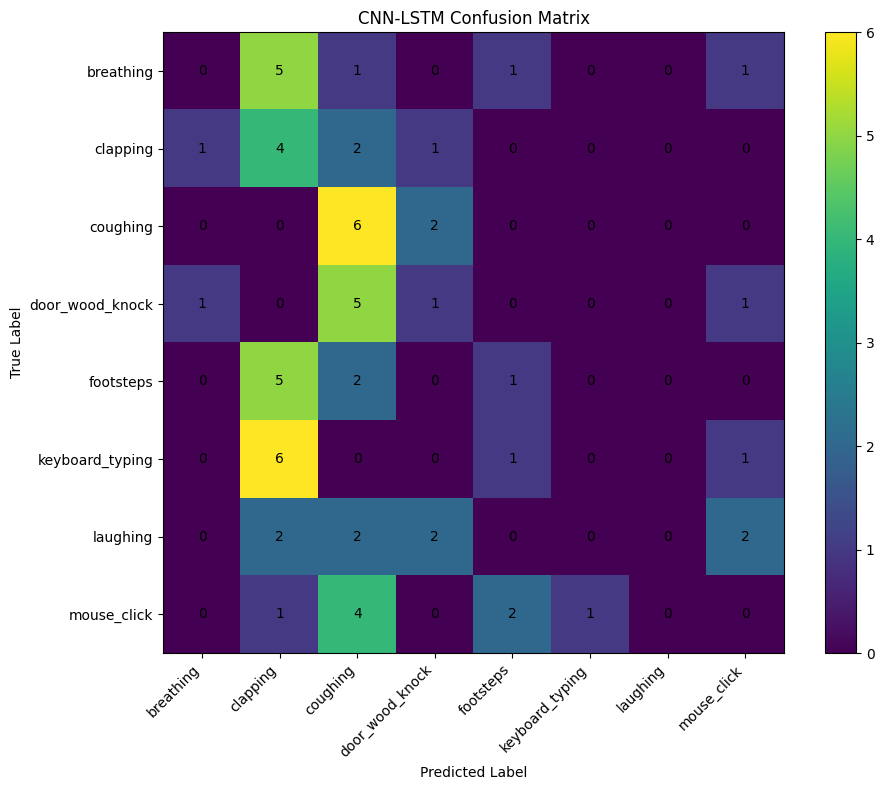

In [81]:
# ============================================================
# CELL 26 — CNN-LSTM CONFUSION MATRIX
# ============================================================

cm_cnn_lstm = confusion_matrix(
    y_test,
    cnn_lstm_predictions
)

plt.figure(figsize=(10, 8))

plt.imshow(
    cm_cnn_lstm,
    interpolation="nearest"
)

plt.title(
    "CNN-LSTM Confusion Matrix"
)

plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    label_encoder.classes_,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(NUM_CLASSES),
    label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(NUM_CLASSES):

    for j in range(NUM_CLASSES):

        plt.text(
            j,
            i,
            cm_cnn_lstm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [82]:
# ============================================================
# CELL 27 — MODEL COMPARISON
# ============================================================

comparison = pd.DataFrame({

    "Model": [
        "CNN",
        "CNN-LSTM"
    ],

    "Accuracy": [
        cnn_accuracy * 100,
        cnn_lstm_accuracy * 100
    ],

    "Precision": [
        cnn_precision * 100,
        cnn_lstm_precision * 100
    ],

    "Recall": [
        cnn_recall * 100,
        cnn_lstm_recall * 100
    ],

    "F1 Score": [
        cnn_f1 * 100,
        cnn_lstm_f1 * 100
    ]
})

display(
    comparison.round(2)
)

,Model,Accuracy,Precision,Recall,F1 Score
0,CNN,17.19,16.30,17.19,12.62
1,CNN-LSTM,18.75,10.17,18.75,11.93


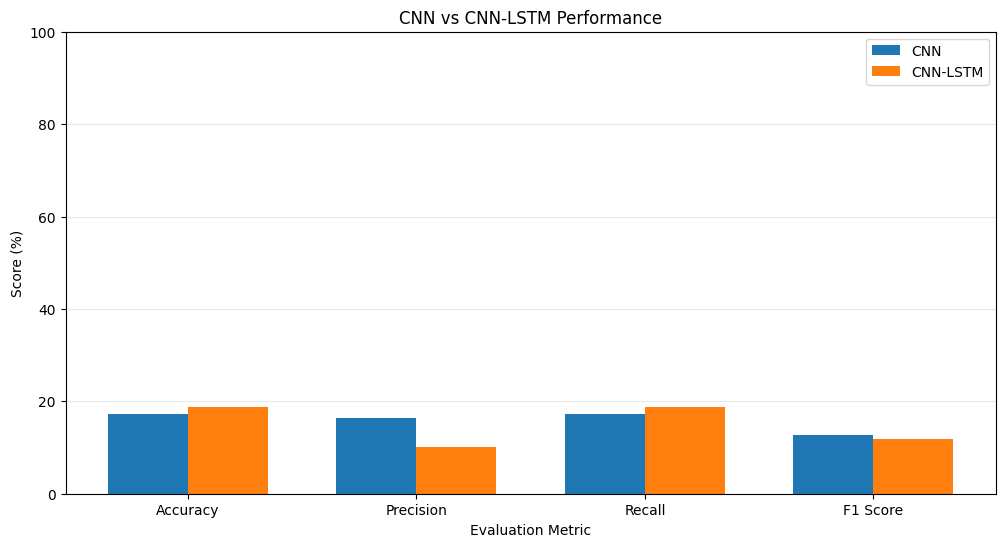

In [83]:
# ============================================================
# CELL 28 — MODEL COMPARISON GRAPH
# ============================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

x = np.arange(
    len(metrics)
)

width = 0.35

plt.figure(figsize=(12, 6))

plt.bar(
    x - width / 2,
    comparison.iloc[0][metrics],
    width,
    label="CNN"
)

plt.bar(
    x + width / 2,
    comparison.iloc[1][metrics],
    width,
    label="CNN-LSTM"
)

plt.xticks(
    x,
    metrics
)

plt.ylabel("Score (%)")

plt.xlabel("Evaluation Metric")

plt.title(
    "CNN vs CNN-LSTM Performance"
)

plt.legend()

plt.ylim(
    0,
    100
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()

In [84]:
# ============================================================
# CELL 29 — SAVE FINAL MODELS
# ============================================================

cnn_model.save(
    "/content/final_cnn_model.keras"
)

cnn_lstm_model.save(
    "/content/final_cnn_lstm_model.keras"
)

print("Models saved successfully!")

print(
    "\nCNN model:"
    "/content/final_cnn_model.keras"
)

print(
    "\nCNN-LSTM model:"
    "/content/final_cnn_lstm_model.keras"
)

Models saved successfully!

CNN model:/content/final_cnn_model.keras

CNN-LSTM model:/content/final_cnn_lstm_model.keras


In [85]:
# ============================================================
# CELL 30 — SELECT BEST MODEL
# ============================================================

if cnn_lstm_accuracy >= cnn_accuracy:

    best_model_name = "CNN-LSTM"
    best_model = cnn_lstm_model
    best_accuracy = cnn_lstm_accuracy

else:

    best_model_name = "CNN"
    best_model = cnn_model
    best_accuracy = cnn_accuracy


print("============================================")
print("FINAL MODEL")
print("============================================")

print(
    "Best model:",
    best_model_name
)

print(
    f"Test accuracy: {best_accuracy * 100:.2f}%"
)

FINAL MODEL
Best model: CNN-LSTM
Test accuracy: 18.75%


In [86]:
# ============================================================
# CELL 31 — SINGLE AUDIO PREDICTION
# ============================================================

def predict_audio(
    file_path,
    model=best_model
):

    # Extract Mel spectrogram
    mel = extract_mel_spectrogram(
        file_path
    )

    # Normalize using training statistics
    mel = (
        mel - train_mean
    ) / (train_std + 1e-8)

    # Add batch and channel dimensions
    mel = mel[np.newaxis, ..., np.newaxis]

    # Prediction
    probabilities = model.predict(
        mel,
        verbose=0
    )[0]

    predicted_index = np.argmax(
        probabilities
    )

    predicted_class = (
        label_encoder.classes_[
            predicted_index
        ]
    )

    confidence = (
        probabilities[
            predicted_index
        ] * 100
    )

    return (
        predicted_class,
        confidence,
        probabilities
    )


# Test using one existing audio file

test_file = os.path.join(
    AUDIO_PATH,
    test_df.iloc[0]["filename"]
)

prediction, confidence, probabilities = (
    predict_audio(test_file)
)

print("============================================")
print("AUDIO PREDICTION")
print("============================================")

print(
    "Actual class:",
    test_df.iloc[0]["category"]
)

print(
    "Predicted class:",
    prediction
)

print(
    f"Confidence: {confidence:.2f}%"
)

AUDIO PREDICTION
Actual class: laughing
Predicted class: coughing
Confidence: 19.95%


In [87]:
# ============================================================
# CELL 32 — PREDICTION PROBABILITIES
# ============================================================

probability_df = pd.DataFrame({

    "Class": label_encoder.classes_,

    "Probability (%)":
        probabilities * 100

})

probability_df = probability_df.sort_values(
    "Probability (%)",
    ascending=False
)

display(
    probability_df.round(2)
)

,Class,Probability (%)
2,coughing,19.950001
7,mouse_click,16.580000
3,door_wood_knock,15.490000
6,laughing,13.100000
5,keyboard_typing,9.590000
0,breathing,8.740000
1,clapping,8.680000
4,footsteps,7.870000


In [88]:
# ============================================================
# TRANSFER LEARNING MODEL — MOBILE NET V2
# ============================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [89]:
# ============================================================
# PREPARE DATA FOR TRANSFER LEARNING
# ============================================================

IMG_SIZE = 224

def prepare_for_mobilenet(X):
    # Convert numpy array to float32
    X = X.astype(np.float32)

    # Add channel dimension if required
    if len(X.shape) == 3:
        X = X[..., np.newaxis]

    # Convert grayscale spectrogram to 3 channels
    X = np.repeat(X, 3, axis=-1)

    # Resize to MobileNetV2 input size
    X = tf.image.resize(
        X,
        (IMG_SIZE, IMG_SIZE)
    )

    return X.numpy()


X_train_mobilenet = prepare_for_mobilenet(X_train_cnn)
X_val_mobilenet = prepare_for_mobilenet(X_val_cnn)
X_test_mobilenet = prepare_for_mobilenet(X_test_cnn)

print("Training shape :", X_train_mobilenet.shape)
print("Validation shape:", X_val_mobilenet.shape)
print("Testing shape  :", X_test_mobilenet.shape)

Training shape : (192, 224, 224, 3)
Validation shape: (64, 224, 224, 3)
Testing shape  : (64, 224, 224, 3)


In [90]:
# ============================================================
# MOBILE NET V2 TRANSFER LEARNING MODEL
# ============================================================

import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import MobileNetV2

# ------------------------------------------------------------
# CLASS NAMES
# ------------------------------------------------------------

CLASS_NAMES = [
    "breathing",
    "clapping",
    "coughing",
    "door_wood_knock",
    "footsteps",
    "keyboard_typing",
    "laughing",
    "mouse_click"
]

NUM_CLASSES = len(CLASS_NAMES)

print("Number of classes:", NUM_CLASSES)
print("Classes:", CLASS_NAMES)


# ------------------------------------------------------------
# LOAD PRETRAINED MOBILENETV2
# ------------------------------------------------------------

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model.trainable = False


# ------------------------------------------------------------
# MODEL INPUT
# ------------------------------------------------------------

inputs = layers.Input(
    shape=(224, 224, 3)
)


# ------------------------------------------------------------
# DATA AUGMENTATION
# ------------------------------------------------------------

x = layers.RandomTranslation(
    height_factor=0.02,
    width_factor=0.08
)(inputs)

x = layers.RandomContrast(0.15)(x)


# ------------------------------------------------------------
# PRETRAINED FEATURE EXTRACTION
# ------------------------------------------------------------

x = base_model(
    x,
    training=False
)


# ------------------------------------------------------------
# CLASSIFICATION HEAD
# ------------------------------------------------------------

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dense(
    256,
    activation="relu"
)(x)

x = layers.Dropout(0.4)(x)

x = layers.Dense(
    128,
    activation="relu"
)(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)


# ------------------------------------------------------------
# CREATE MODEL
# ------------------------------------------------------------

transfer_model = Model(
    inputs=inputs,
    outputs=outputs
)


# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

transfer_model.summary()

Number of classes: 8
Classes: ['breathing', 'clapping', 'coughing', 'door_wood_knock', 'footsteps', 'keyboard_typing', 'laughing', 'mouse_click']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_3            │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_3               │ (None, 224, 224, 3)    │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_20 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_21 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,624,968 (10.01 MB)

 Trainable params: 364,424 (1.39 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [91]:
# ============================================================
# CALLBACKS
# ============================================================

transfer_callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_accuracy",
        patience=8,
        mode="max",
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_mobilenet_model.keras",
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    )
]

In [92]:
# ============================================================
# PHASE 1 — TRAIN CLASSIFICATION HEAD
# ============================================================

history_transfer_1 = transfer_model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(
        X_val_mobilenet,
        y_val
    ),
    epochs=30,
    batch_size=16,
    callbacks=transfer_callbacks,
    verbose=1
)

Epoch 1/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.0625 - loss: 3.0015
Epoch 1: val_accuracy improved from None to 0.15625, saving model to /content/best_mobilenet_model.keras

Epoch 1: finished saving model to /content/best_mobilenet_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 10s 410ms/step - accuracy: 0.0885 - loss: 2.7461 - val_accuracy: 0.1562 - val_loss: 2.1079 - learning_rate: 1.0000e-04
Epoch 2/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.1722 - loss: 2.4800
Epoch 2: val_accuracy improved from 0.15625 to 0.25000, saving model to /content/best_mobilenet_model.keras

Epoch 2: finished saving model to /content/best_mobilenet_model.keras
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 109ms/step - accuracy: 0.2292 - loss: 2.2070 - val_accuracy: 0.2500 - val_loss: 1.9460 - learning_rate: 1.0000e-04
Epoch 3/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3684 - loss: 1.7017
Epoch 3: val_accuracy improved from 0.25000 to 0.35938, saving model to /content/best_mobilenet_mod

In [93]:
# ============================================================
# PHASE 2 — FINE TUNING
# ============================================================

# Unfreeze the MobileNetV2
base_model.trainable = True

# Freeze the earlier layers
# Fine-tune only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

# Recompile with a much smaller learning rate
transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable layers:",
      sum(layer.trainable for layer in transfer_model.layers))

Trainable layers: 11


In [94]:
# ============================================================
# FINE-TUNE MODEL
# ============================================================

history_transfer_2 = transfer_model.fit(
    X_train_mobilenet,
    y_train,
    validation_data=(
        X_val_mobilenet,
        y_val
    ),
    epochs=30,
    batch_size=16,
    callbacks=transfer_callbacks,
    verbose=1
)

Epoch 1/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.8116 - loss: 0.5805
Epoch 1: val_accuracy did not improve from 0.75000
12/12 ━━━━━━━━━━━━━━━━━━━━ 9s 278ms/step - accuracy: 0.8229 - loss: 0.5504 - val_accuracy: 0.7188 - val_loss: 0.9004 - learning_rate: 1.0000e-05
Epoch 2/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.8404 - loss: 0.5148
Epoch 2: val_accuracy did not improve from 0.75000
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - accuracy: 0.8438 - loss: 0.4870 - val_accuracy: 0.7188 - val_loss: 0.9227 - learning_rate: 1.0000e-05
Epoch 3/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.8141 - loss: 0.5552
Epoch 3: val_accuracy did not improve from 0.75000
12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 0.8438 - loss: 0.4532 - val_accuracy: 0.7500 - val_loss: 0.8970 - learning_rate: 1.0000e-05
Epoch 4/30
11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8519 - loss: 0.5429
Epoch 4: val_accuracy did not improve from 0.75000
12/12 ━━━━━━━━━━━━━━━━━

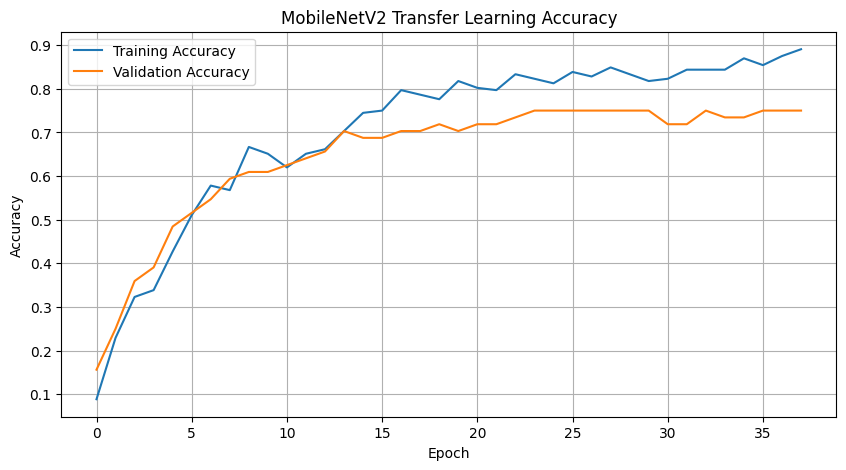

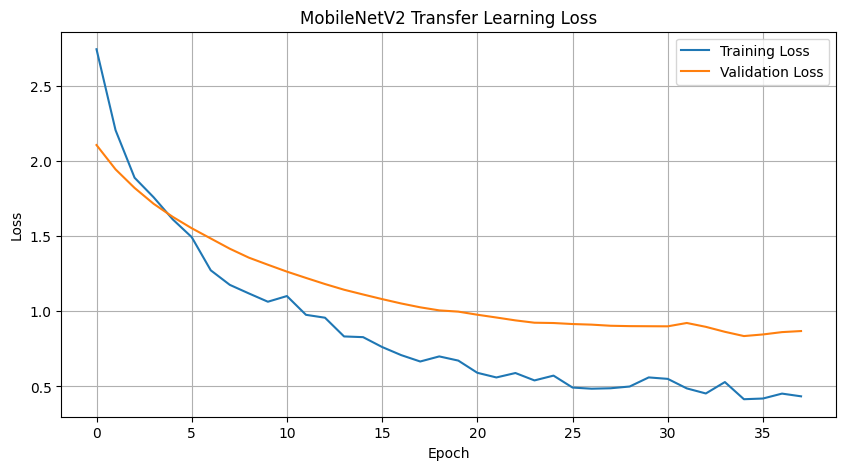

In [95]:
# ============================================================
# TRANSFER LEARNING TRAINING GRAPHS
# ============================================================

acc1 = history_transfer_1.history["accuracy"]
val_acc1 = history_transfer_1.history["val_accuracy"]

acc2 = history_transfer_2.history["accuracy"]
val_acc2 = history_transfer_2.history["val_accuracy"]

loss1 = history_transfer_1.history["loss"]
val_loss1 = history_transfer_1.history["val_loss"]

loss2 = history_transfer_2.history["loss"]
val_loss2 = history_transfer_2.history["val_loss"]

train_acc = acc1 + acc2
val_acc = val_acc1 + val_acc2

train_loss = loss1 + loss2
val_loss = val_loss1 + val_loss2


plt.figure(figsize=(10, 5))

plt.plot(train_acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Transfer Learning Accuracy")

plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 5))

plt.plot(train_loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Transfer Learning Loss")

plt.legend()
plt.grid(True)
plt.show()

In [96]:
# ============================================================
# MOBILE NET V2 TEST PERFORMANCE
# ============================================================

transfer_test_loss, transfer_test_accuracy = transfer_model.evaluate(
    X_test_mobilenet,
    y_test,
    verbose=1
)

print("=" * 60)
print("MOBILE NET V2 TEST PERFORMANCE")
print("=" * 60)

print(
    f"Test Accuracy : {transfer_test_accuracy * 100:.2f}%"
)

print(
    f"Test Loss     : {transfer_test_loss:.4f}"
)

print("=" * 60)

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.6719 - loss: 1.0298
MOBILE NET V2 TEST PERFORMANCE
Test Accuracy : 67.19%
Test Loss     : 1.0298


In [97]:
# ============================================================
# DETAILED MOBILE NET V2 METRICS
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

transfer_probabilities = transfer_model.predict(
    X_test_mobilenet
)

transfer_predictions = np.argmax(
    transfer_probabilities,
    axis=1
)

transfer_accuracy = accuracy_score(
    y_test,
    transfer_predictions
)

transfer_precision = precision_score(
    y_test,
    transfer_predictions,
    average="weighted",
    zero_division=0
)

transfer_recall = recall_score(
    y_test,
    transfer_predictions,
    average="weighted",
    zero_division=0
)

transfer_f1 = f1_score(
    y_test,
    transfer_predictions,
    average="weighted",
    zero_division=0
)

print("=" * 60)
print("MOBILE NET V2 PERFORMANCE")
print("=" * 60)

print(f"Accuracy  : {transfer_accuracy * 100:.2f}%")
print(f"Precision : {transfer_precision * 100:.2f}%")
print(f"Recall    : {transfer_recall * 100:.2f}%")
print(f"F1 Score  : {transfer_f1 * 100:.2f}%")

print("=" * 60)

print("\nCLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        transfer_predictions,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step
MOBILE NET V2 PERFORMANCE
Accuracy  : 67.19%
Precision : 74.06%
Recall    : 67.19%
F1 Score  : 66.22%

CLASSIFICATION REPORT
                 precision    recall  f1-score   support

      breathing       0.60      0.75      0.67         8
       clapping       0.70      0.88      0.78         8
       coughing       1.00      0.25      0.40         8
door_wood_knock       0.88      0.88      0.88         8
      footsteps       0.78      0.88      0.82         8
keyboard_typing       0.56      0.62      0.59         8
       laughing       1.00      0.50      0.67         8
    mouse_click       0.42      0.62      0.50         8

       accuracy                           0.67        64
      macro avg       0.74      0.67      0.66        64
   weighted avg       0.74      0.67      0.66        64



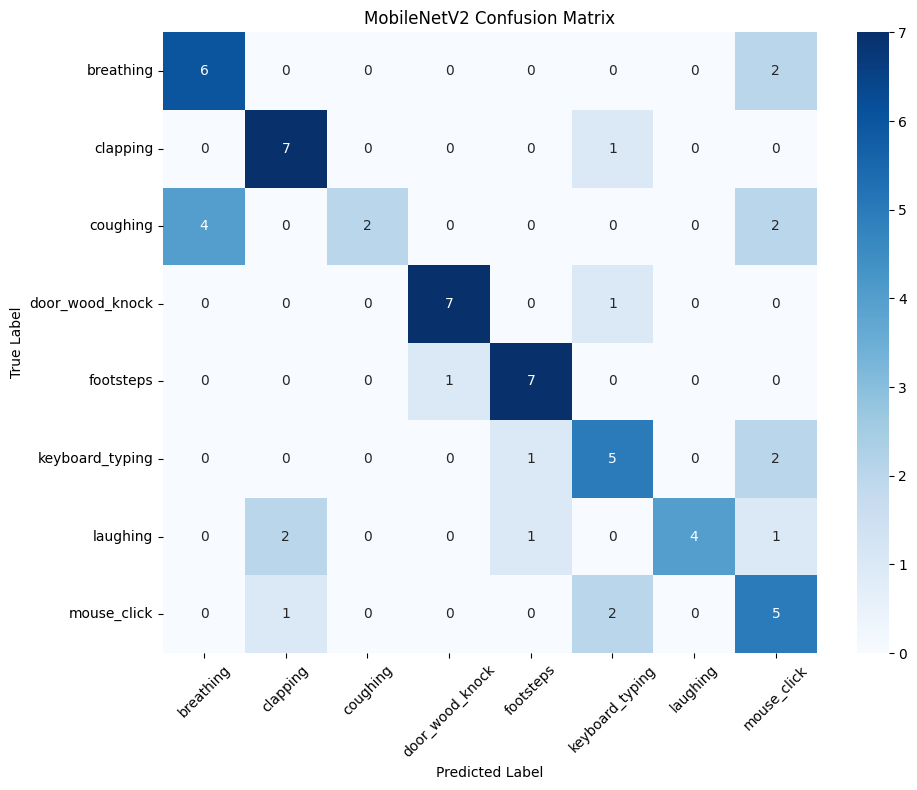

In [98]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

import seaborn as sns

cm = confusion_matrix(
    y_test,
    transfer_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("MobileNetV2 Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [99]:
# ============================================================
# CNN vs MOBILENETV2 — FINAL MODEL COMPARISON
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# CNN METRICS
# ------------------------------------------------------------

cnn_accuracy_final = accuracy_score(
    y_test,
    cnn_predictions
)

cnn_precision_final = precision_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

cnn_recall_final = recall_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)

cnn_f1_final = f1_score(
    y_test,
    cnn_predictions,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# MOBILENETV2 PREDICTIONS
# ------------------------------------------------------------

transfer_probabilities = transfer_model.predict(
    X_test_mobilenet,
    verbose=0
)

transfer_predictions = np.argmax(
    transfer_probabilities,
    axis=1
)


# ------------------------------------------------------------
# MOBILENETV2 METRICS
# ------------------------------------------------------------

transfer_accuracy_final = accuracy_score(
    y_test,
    transfer_predictions
)

transfer_precision_final = precision_score(
    y_test,
    transfer_predictions,
    average="weighted",
    zero_division=0
)

transfer_recall_final = recall_score(
    y_test,
    transfer_predictions,
    average="weighted",
    zero_division=0
)

transfer_f1_final = f1_score(
    y_test,
    transfer_predictions,
    average="weighted",
    zero_division=0
)


# ------------------------------------------------------------
# DISPLAY COMPARISON
# ------------------------------------------------------------

print("=" * 70)
print("                 MODEL PERFORMANCE COMPARISON")
print("=" * 70)

print(
    f"{'Metric':<25}"
    f"{'CNN':<20}"
    f"{'MobileNetV2':<20}"
)

print("-" * 70)

print(
    f"{'Accuracy':<25}"
    f"{cnn_accuracy_final * 100:<20.2f}"
    f"{transfer_accuracy_final * 100:<20.2f}"
)

print(
    f"{'Precision':<25}"
    f"{cnn_precision_final * 100:<20.2f}"
    f"{transfer_precision_final * 100:<20.2f}"
)

print(
    f"{'Recall':<25}"
    f"{cnn_recall_final * 100:<20.2f}"
    f"{transfer_recall_final * 100:<20.2f}"
)

print(
    f"{'F1 Score':<25}"
    f"{cnn_f1_final * 100:<20.2f}"
    f"{transfer_f1_final * 100:<20.2f}"
)

print("=" * 70)


# ------------------------------------------------------------
# IMPROVEMENT
# ------------------------------------------------------------

accuracy_improvement = (
    transfer_accuracy_final - cnn_accuracy_final
) * 100

relative_improvement = (
    (transfer_accuracy_final - cnn_accuracy_final)
    / cnn_accuracy_final
) * 100

print("\nIMPROVEMENT")
print("=" * 70)

print(
    f"Absolute Accuracy Improvement : "
    f"{accuracy_improvement:.2f} percentage points"
)

print(
    f"Relative Accuracy Improvement : "
    f"{relative_improvement:.2f}%"
)

print("=" * 70)

                 MODEL PERFORMANCE COMPARISON
Metric                   CNN                 MobileNetV2         
----------------------------------------------------------------------
Accuracy                 17.19               67.19               
Precision                16.30               74.06               
Recall                   17.19               67.19               
F1 Score                 12.62               66.22               

IMPROVEMENT
Absolute Accuracy Improvement : 50.00 percentage points
Relative Accuracy Improvement : 290.91%


In [100]:
# ============================================================
# MOBILENETV2 — DETAILED CLASSIFICATION REPORT
# ============================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("       MOBILENETV2 CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        transfer_predictions,
        target_names=CLASS_NAMES,
        zero_division=0
    )
)

       MOBILENETV2 CLASSIFICATION REPORT
                 precision    recall  f1-score   support

      breathing       0.60      0.75      0.67         8
       clapping       0.70      0.88      0.78         8
       coughing       1.00      0.25      0.40         8
door_wood_knock       0.88      0.88      0.88         8
      footsteps       0.78      0.88      0.82         8
keyboard_typing       0.56      0.62      0.59         8
       laughing       1.00      0.50      0.67         8
    mouse_click       0.42      0.62      0.50         8

       accuracy                           0.67        64
      macro avg       0.74      0.67      0.66        64
   weighted avg       0.74      0.67      0.66        64



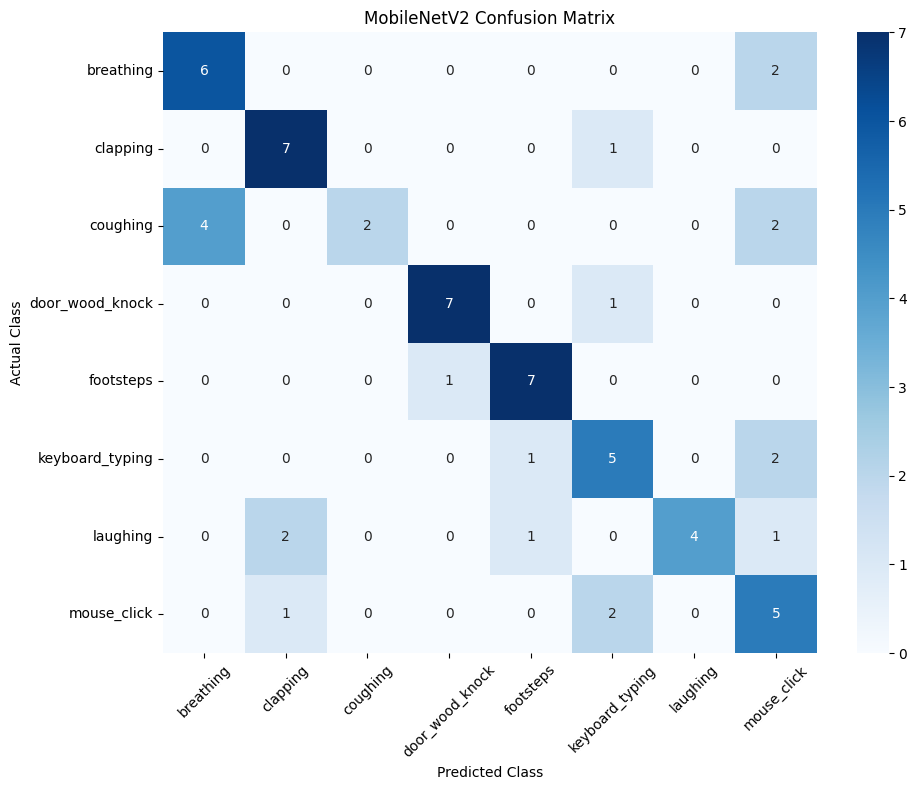

In [101]:
# ============================================================
# MOBILENETV2 — CONFUSION MATRIX
# ============================================================

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    transfer_predictions
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 Confusion Matrix")

plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()